# Online Food Ordering Dataset Jupyter Notebook

* **Methodology:** Data cleaning, demographic segmentation, spatial analysis, and behavioral distribution profiling.
* **Tech Stack:** Python, Pandas, Seaborn, Matplotlib, and Jupyter Notebooks.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.size': 11, 'figure.autolayout': True})

df = pd.read_csv('online food delivery dataset.csv')

if 'Unnamed: 13' in df.columns:
  df = df.drop(columns=['Unnamed: 13'])
df = df.drop_duplicates()

print(f'Dataset shape after cleaning: {df.shape}')

Dataset shape after cleaning: (285, 13)


---
## 1. Marital Status vs. Monthly Income (Heatmap)

### Prompt Strategy
Constructed a cross-tabulated heatmap to visualize customer concentration density across marital status and income brackets simultaneously.

### Visualization Code

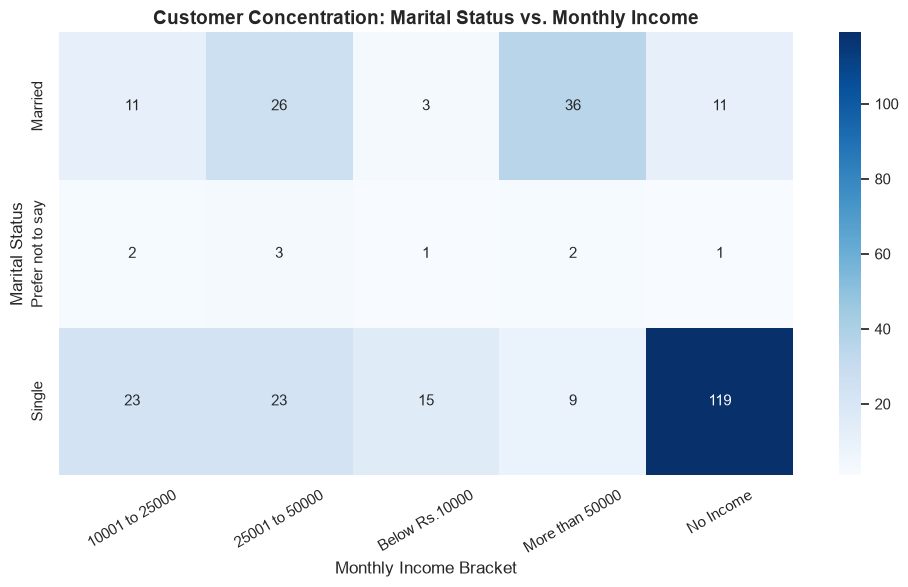

In [2]:
plt.figure(figsize=(10, 6))
heatmap_data = pd.crosstab(df['Marital Status'], df['Monthly Income'])
sns.heatmap(heatmap_data, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.title(
    'Customer Concentration: Marital Status vs. Monthly Income',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Monthly Income Bracket')
plt.ylabel('Marital Status')
plt.xticks(rotation=30)
plt.savefig('viz1.png', dpi=300)
plt.show()

### Analysis & Key Insights
* **Single vs. Married Segments:** Single customers predominantly cluster in the lower income/no income brackets (students), whereas married customers show higher concentrations in mid-to-high income brackets.
* **Promotional Strategy:** Offers targeting single users should focus on discounts and budget meals, while married user segments are better suited for family-sized meal deals.

---
## 2. Geographic Distribution (Latitude vs. Longitude Scatter Map)

### Prompt Strategy
Mapped spatial coordinates (`latitude` and `longitude`) to identify geographical clustering, hue-coded by customer feedback and styled by gender.

### Visualization Code

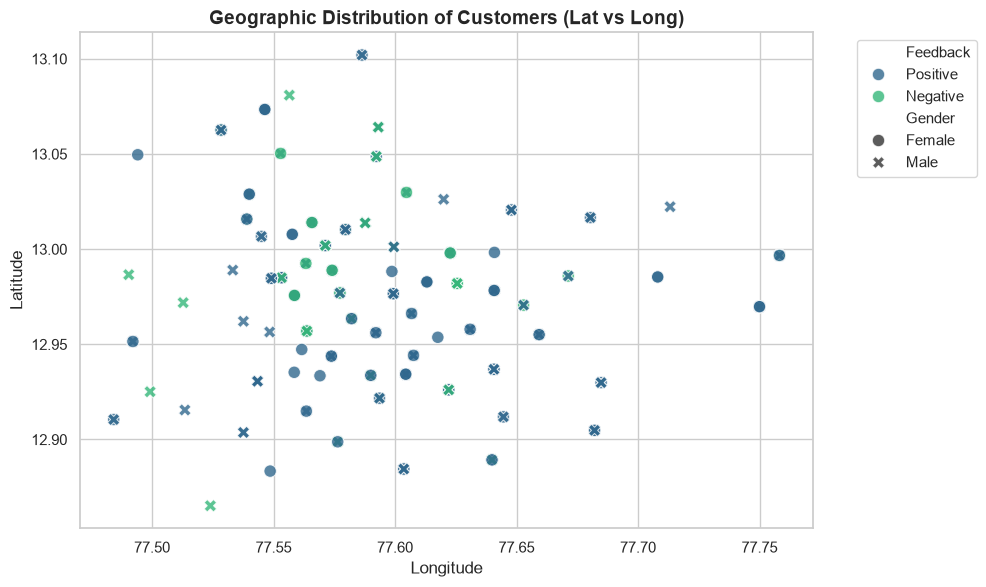

In [3]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='longitude',
    y='latitude',
    hue='Feedback',
    style='Gender',
    s=80,
    palette='viridis',
    alpha=0.8,
)
plt.title(
    'Geographic Distribution of Customers (Lat vs Long)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('viz2.png', dpi=300)
plt.show()

### Analysis & Key Insights
* **Spatial Clusters:** Deliveries are highly concentrated in specific urban coordinate clusters.
* **Service Coverage:** Negative feedback points are distributed evenly across geographic clusters rather than isolated to remote locations, suggesting order quality issue rather than delivery range issues.

---
## 3. Educational Qualifications & Order Status (Countplot)

### Prompt Strategy
Designed a categorical count plot sorted by group frequency to analyze how education level impacts platform adoption and continued usage.

### Visualization Code

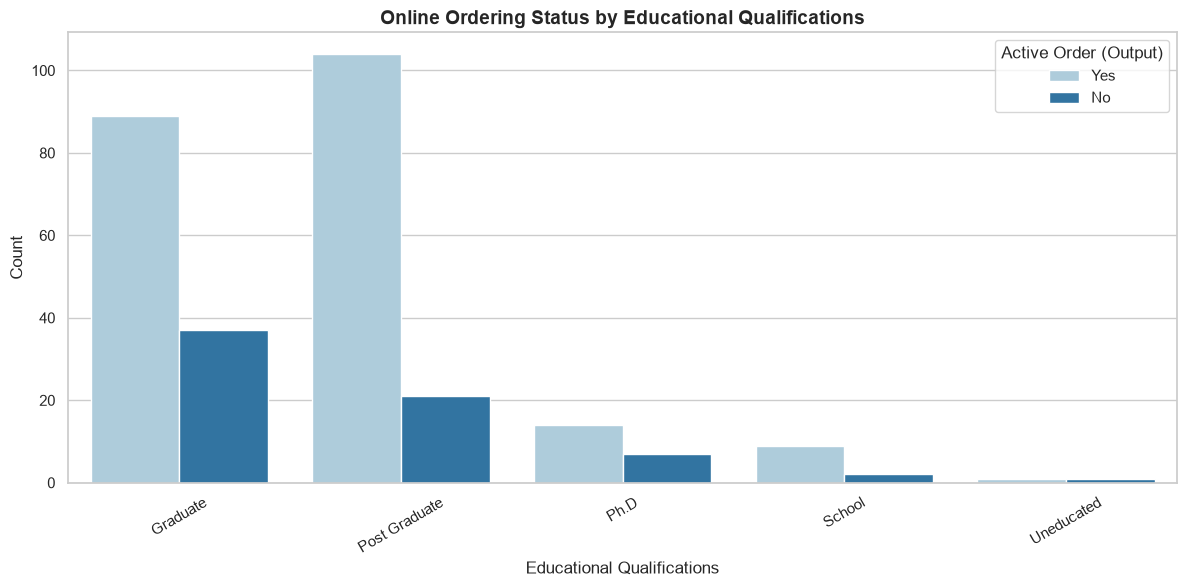

In [4]:
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    x='Educational Qualifications',
    hue='Output',
    palette='Paired',
    order=df['Educational Qualifications'].value_counts().index,
)
plt.title(
    'Online Ordering Status by Educational Qualifications',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Educational Qualifications')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.legend(title='Active Order (Output)')
plt.savefig('viz3.png', dpi=300)
plt.show()

### Analysis & Key Insights
* **Graduates & Post-Graduates:** Account for the majority of orders, with high retention rates (`Output = Yes`).
* **Target Audience:** Digital food ordering marketing campaigns yield higher conversion rates when directed at university-educated demographics.

---
## 4. Feedback Proportions by Customer Type (Donut Chart)

### Prompt Strategy
Built side-by-side donut charts using subplots, leveraging custom wedge styling and `pctdistance` adjustment to keep percentage values neatly placed within the colored rings.

### Visualization Code

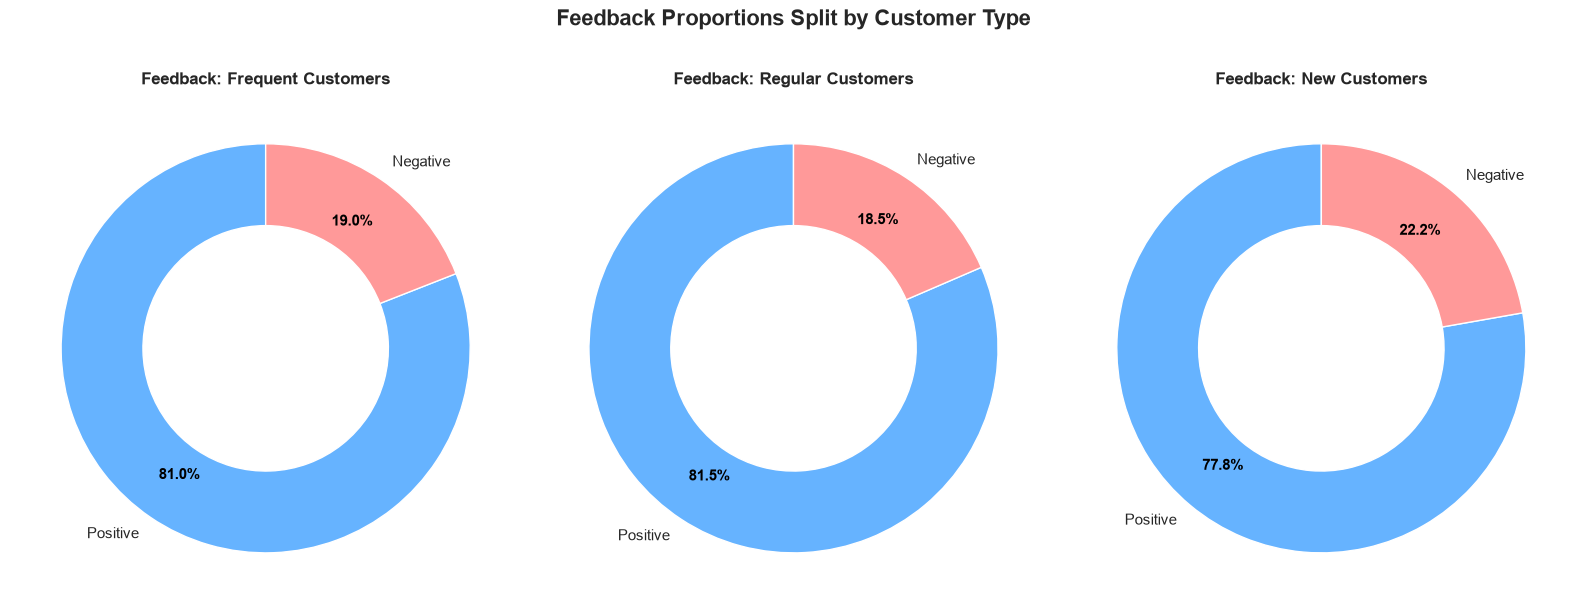

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
customer_types = df['Customer Type'].unique()

for i, c_type in enumerate(customer_types):
  subset = df[df['Customer Type'] == c_type]['Feedback'].value_counts()
  wedges, texts, autotexts = axes[i].pie(
      subset,
      labels=subset.index,
      autopct='%1.1f%%',
      startangle=90,
      colors=['#66b3ff', '#ff9999'],
      wedgeprops=dict(width=0.4, edgecolor='w'),
      pctdistance=0.75,
  )
  for autotext in autotexts:
    autotext.set_color('black')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(11)

  axes[i].set_title(f'Feedback: {c_type} Customers', fontweight='bold')

plt.suptitle(
    'Feedback Proportions Split by Customer Type',
    fontsize=16,
    fontweight='bold',
    y=1.02,
)
plt.savefig('viz4.png', dpi=300)
plt.show()

### Analysis & Key Insights
* **High Satisfaction:** Over **77%** of feedback is positive across all customer tiers.
* **Onboarding Friction:** New customers report the highest negative feedback proportion (**22.2%**), indicating that initial platform experience or first delivery times could be improved.

---
## 5. Family Size vs. Age (Box & Swarm Plot)

### Prompt Strategy
Combined a box plot with an overlaid stripplot/swarmplot to show both summary statistics (quartiles, medians) and individual data points across household sizes.

### Visualization Code

C:\Users\Summer\AppData\Local\Temp\ipykernel_37100\776555364.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


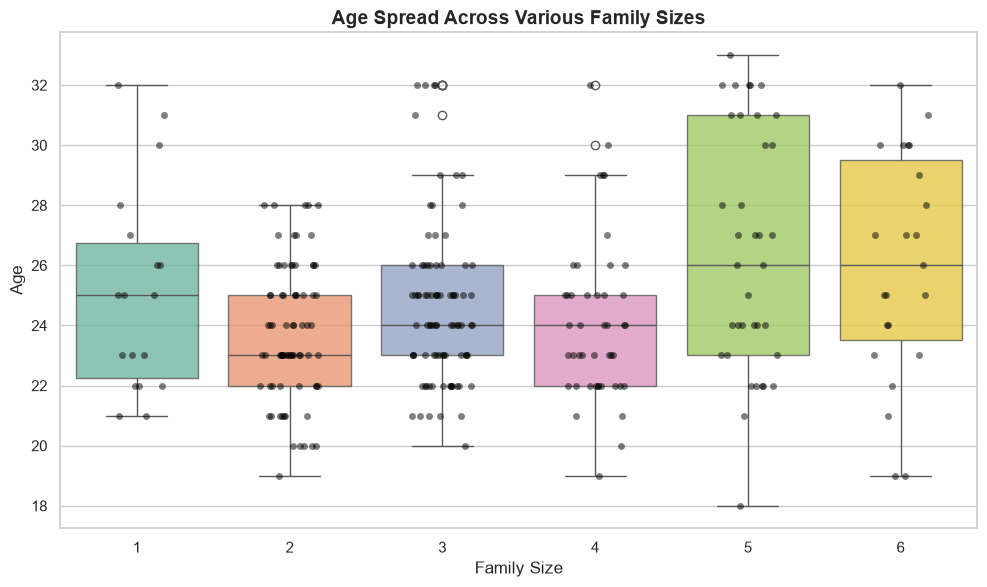

In [6]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x='Family size',
    y='Age',
    palette='Set2',
    boxprops=dict(alpha=0.8),
)
sns.stripplot(data=df, x='Family size', y='Age', color='black', alpha=0.5, jitter=0.2)
plt.title(
    'Age Spread Across Various Family Sizes', fontsize=14, fontweight='bold'
)
plt.xlabel('Family Size')
plt.ylabel('Age')
plt.savefig('viz5_familysize_age.png', dpi=300)
plt.show()

### Analysis & Key Insights
* **Household Dynamics:** Larger family sizes (5+ members) show a slightly higher median age compared to single or small households.
* **Core Segment:** Households of 2 to 4 members represent the core user base across almost all age brackets.

---
## 6. Occupation vs. Monthly Income (Stacked Bar Chart)

### Prompt Strategy
Created a stacked bar chart using Pandas cross-tabulation to visualize the income distribution across different employment segments.

### Visualization Code

<Figure size 1200x600 with 0 Axes>

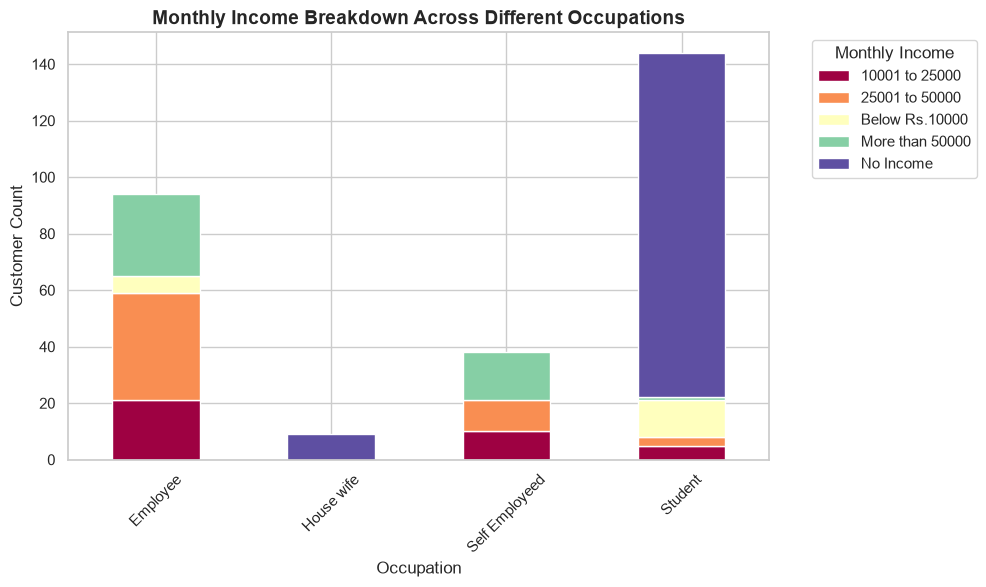

In [7]:
plt.figure(figsize=(12, 6))
income_occupation = pd.crosstab(df['Occupation'], df['Monthly Income'])
income_occupation.plot(
    kind='bar', stacked=True, colormap='Spectral', figsize=(10, 6)
)
plt.title(
    'Monthly Income Breakdown Across Different Occupations',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Occupation')
plt.ylabel('Customer Count')
plt.xticks(rotation=45)
plt.legend(title='Monthly Income', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('viz6.png', dpi=300)
plt.show()

### Analysis & Key Insights
* **Student Dominance:** Students form the largest individual customer segment, naturally clustering in the "No Income" category.
* **Salaried Employees:** Employed customers exhibit a balanced spread across higher income brackets (e.g., 25,000+ per month), making them higher-value targets for premium offers.

---
## 7. Age Distribution by Order Output (KDE Plot)

### Prompt Strategy
Requested a combined histogram and Kernel Density Estimation (KDE) plot to understand how customer age correlates with active/continued food ordering behavior (`Output`).

### Visualization Code

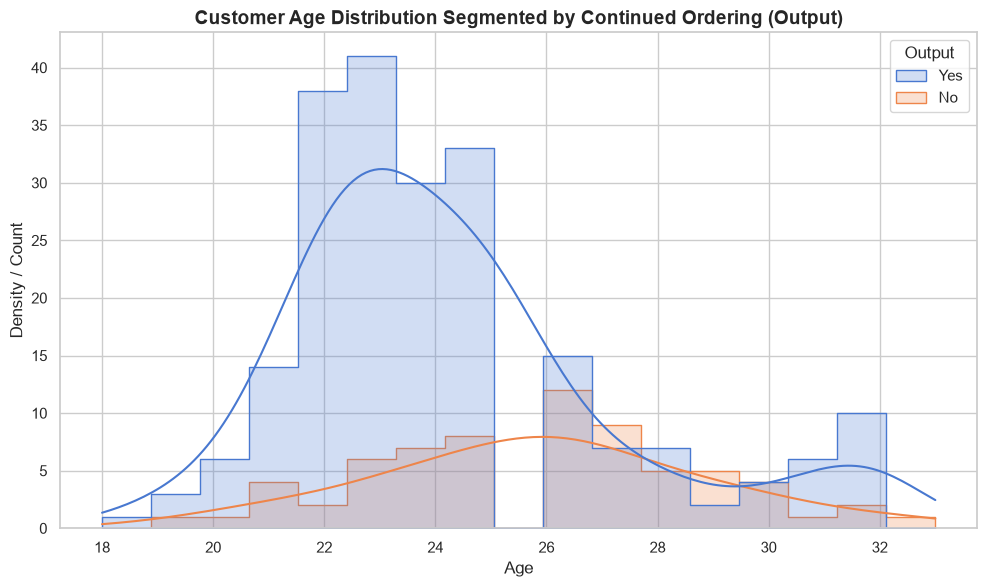

In [8]:
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x='Age',
    hue='Output',
    element='step',
    common_norm=False,
    palette='muted',
    kde=True,
)
plt.title(
    'Customer Age Distribution Segmented by Continued Ordering (Output)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Age')
plt.ylabel('Density / Count')
plt.savefig('viz1_age_distribution.png', dpi=300)
plt.show()

### Analysis & Key Insights
* **Demographic Peak:** The primary demographic using the service ranges between **20 and 25 years old**.
* **Churn / Drop-off:** Retention (`Output = Yes`) is highest among younger adults, whereas older age demographics show a higher ratio of discontinued orders (`Output = No`).